<a href="https://colab.research.google.com/github/keerthanajeyashree25-eng/AI-Government-Assistant/blob/main/Advanced_Statistical_Analysis_Hypothesis_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Statistical Analysis & Hypothesis Testing

**Dataset:** Seaborn Tips (restaurant business data)  
**Objective:** Explore customer bills and tips using normality tests, two-sample tests, one-way and two-way ANOVA, and Tukey HSD post-hoc comparisons.

> The notebook downloads the public Tips dataset when run. An internet connection is required for the first data-loading step.

## Research questions
1. Are the numeric variables approximately normally distributed?
2. Do smokers and non-smokers have different tip percentages?
3. Does the average total bill differ by day?
4. Do day and customer sex, and their interaction, relate to total bill?

## Significance level
Set \(\alpha = 0.05\). A p-value below 0.05 is treated as statistically significant. Statistical significance does not by itself imply practical importance or causation.


In [ ]:
# Install any missing packages in Jupyter if needed:
# %pip install pandas numpy scipy seaborn matplotlib statsmodels

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multicomp import pairwise_tukeyhsd

ALPHA = 0.05
sns.set_theme(style="whitegrid")

# Public dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
print("Dataset shape:", df.shape)
print("\\nColumn information:")
df.info()
print("\\nMissing values:")
print(df.isnull().sum())
print("\\nSummary statistics:")
display(df.describe(include="all"))

Dataset shape: (244, 7)
\nColumn information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB
\nMissing values:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
\nSummary statistics:


,total_bill,tip,sex,smoker,day,time,size
count,244.000000,244.000000,244,244,244,244,244.000000
unique,NaN,NaN,2,2,4,2,NaN
top,NaN,NaN,Male,No,Sat,Dinner,NaN
freq,NaN,NaN,157,151,87,176,NaN
mean,19.785943,2.998279,NaN,NaN,NaN,NaN,2.569672
std,8.902412,1.383638,NaN,NaN,NaN,NaN,0.951100
min,3.070000,1.000000,NaN,NaN,NaN,NaN,1.000000
25%,13.347500,2.000000,NaN,NaN,NaN,NaN,2.000000
50%,17.795000,2.900000,NaN,NaN,NaN,NaN,2.000000
75%,24.127500,3.562500,NaN,NaN,NaN,NaN,3.000000


## 1. Prepare analysis variables

We calculate tip percentage so that tips can be compared relative to bill size. We use complete observations for the variables in this analysis.

In [3]:
df = df.dropna().copy()
df["tip_pct"] = (df["tip"] / df["total_bill"]) * 100

print("Rows after removing missing values:", len(df))
display(df[["total_bill", "tip", "tip_pct", "day", "sex", "smoker"]].head())

Rows after removing missing values: 244


,total_bill,tip,tip_pct,day,sex,smoker
0,16.99,1.01,5.944673,Sun,Female,No
1,10.34,1.66,16.054159,Sun,Male,No
2,21.01,3.50,16.658734,Sun,Male,No
3,23.68,3.31,13.978041,Sun,Male,No
4,24.59,3.61,14.680765,Sun,Female,No


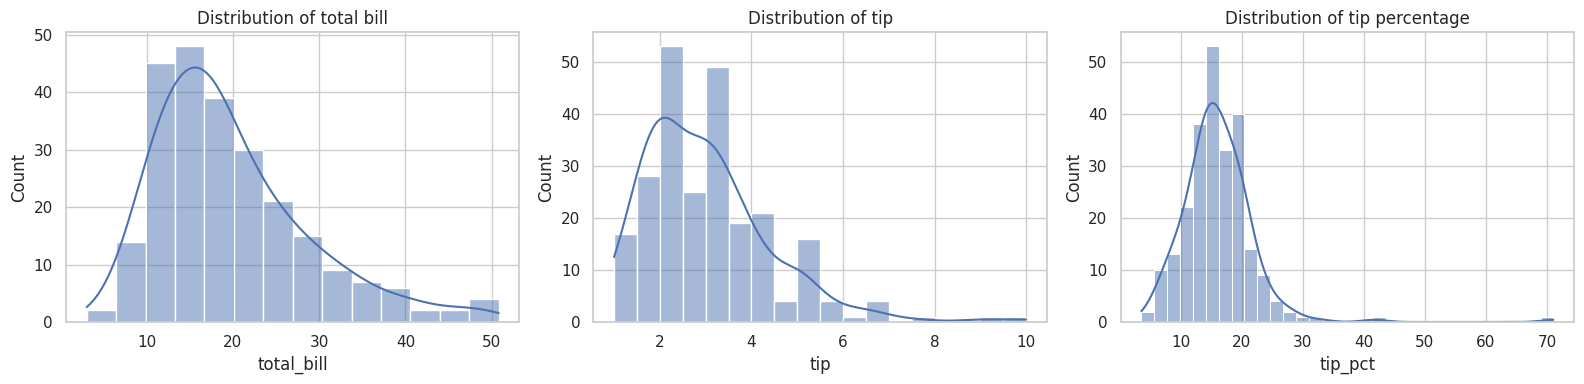

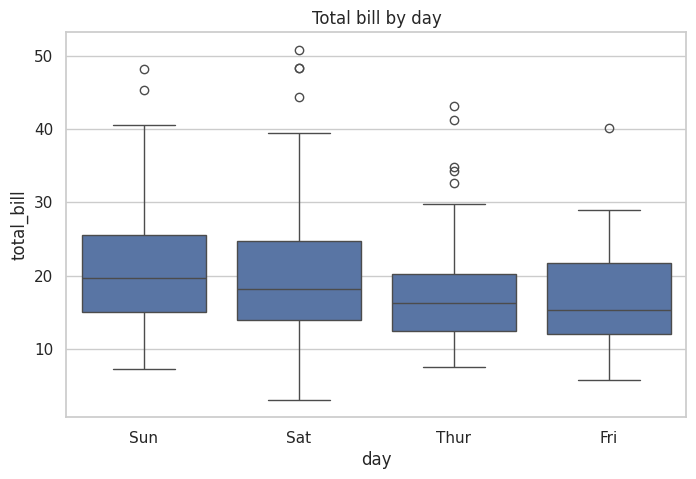

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["total_bill"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of total bill")
sns.histplot(df["tip"], kde=True, ax=axes[1])
axes[1].set_title("Distribution of tip")
sns.histplot(df["tip_pct"], kde=True, ax=axes[2])
axes[2].set_title("Distribution of tip percentage")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="day", y="total_bill")
plt.title("Total bill by day")
plt.show()

## 2. Normality tests

**Null hypothesis (H₀):** The sample is drawn from a normally distributed population.  
**Alternative hypothesis (H₁):** The sample is not drawn from a normally distributed population.

- Shapiro-Wilk is used for the normality test.
- The Kolmogorov-Smirnov test is applied with the Lilliefors correction because the normal mean and standard deviation are estimated from the sample. This avoids using the ordinary KS p-value as though the parameters were known in advance.
- A p-value below 0.05 gives evidence against normality. With large samples, tests can detect small departures, so plots should also be inspected.

In [5]:
normality_results = []

for column in ["total_bill", "tip", "tip_pct"]:
    sample = df[column].sample(n=min(len(df), 5000), random_state=42)
    shapiro_stat, shapiro_p = stats.shapiro(sample)
    ks_stat, ks_p = lilliefors(sample, dist="norm")
    normality_results.append({
        "Variable": column,
        "Shapiro statistic": shapiro_stat,
        "Shapiro p-value": shapiro_p,
        "Lilliefors KS statistic": ks_stat,
        "Lilliefors KS p-value": ks_p
    })

normality_table = pd.DataFrame(normality_results)
display(normality_table)

for _, row in normality_table.iterrows():
    print(f"\\n{row['Variable']}:")
    print("Shapiro-Wilk:", "Evidence against normality" if row["Shapiro p-value"] < ALPHA else "No significant evidence against normality")
    print("Lilliefors KS:", "Evidence against normality" if row["Lilliefors KS p-value"] < ALPHA else "No significant evidence against normality")

,Variable,Shapiro statistic,Shapiro p-value,Lilliefors KS statistic,Lilliefors KS p-value
0,total_bill,0.919719,3.324539e-10,0.118754,0.001
1,tip,0.897811,8.200360e-12,0.101653,0.001
2,tip_pct,0.799428,5.118350e-17,0.109556,0.001


\ntotal_bill:
Shapiro-Wilk: Evidence against normality
Lilliefors KS: Evidence against normality
\ntip:
Shapiro-Wilk: Evidence against normality
Lilliefors KS: Evidence against normality
\ntip_pct:
Shapiro-Wilk: Evidence against normality
Lilliefors KS: Evidence against normality


## 3. Two-sample comparison: smokers vs non-smokers

**Outcome:** Tip percentage (`tip_pct`)  
**Groups:** Smokers and non-smokers

**H₀:** The population mean tip percentage is equal for smokers and non-smokers (t-test).  
**H₁:** The population mean tip percentage differs between the groups.

For Mann-Whitney U, the null is that the two group distributions are the same; it is not automatically a test of medians unless distribution shapes are comparable.

We use Welch's independent-samples t-test, which does not assume equal group variances, and a two-sided Mann-Whitney U test.

Smoker n, mean: 93 16.32
Non-smoker n, mean: 151 15.933
\nWelch t-test: statistic = 0.4112 p-value = 0.6816579190889744
95% CI for mean difference (smoker - non-smoker): [-1.476, 2.249] percentage points
Decision: Fail to reject H0
\nMann-Whitney U: statistic = 6709.5 p-value = 0.5607354834435516
Decision: Fail to reject equal-distributions H0


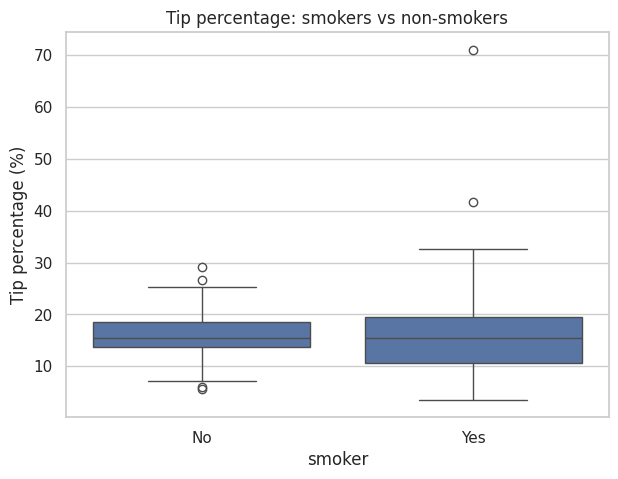

In [6]:
smoker = df.loc[df["smoker"] == "Yes", "tip_pct"]
non_smoker = df.loc[df["smoker"] == "No", "tip_pct"]

# Welch two-sample t-test
t_stat, t_p = stats.ttest_ind(smoker, non_smoker, equal_var=False)

# Welch confidence interval for difference in means (smoker - non-smoker)
mean_diff = smoker.mean() - non_smoker.mean()
se_diff = np.sqrt(smoker.var(ddof=1)/len(smoker) + non_smoker.var(ddof=1)/len(non_smoker))
df_welch = (smoker.var(ddof=1)/len(smoker) + non_smoker.var(ddof=1)/len(non_smoker))**2 / (
    (smoker.var(ddof=1)/len(smoker))**2/(len(smoker)-1) +
    (non_smoker.var(ddof=1)/len(non_smoker))**2/(len(non_smoker)-1)
)
critical_t = stats.t.ppf(1 - ALPHA/2, df_welch)
ci_low = mean_diff - critical_t * se_diff
ci_high = mean_diff + critical_t * se_diff

# Mann-Whitney U
u_stat, u_p = stats.mannwhitneyu(smoker, non_smoker, alternative="two-sided")

print("Smoker n, mean:", len(smoker), round(smoker.mean(), 3))
print("Non-smoker n, mean:", len(non_smoker), round(non_smoker.mean(), 3))
print("\\nWelch t-test: statistic =", round(t_stat, 4), "p-value =", t_p)
print(f"95% CI for mean difference (smoker - non-smoker): [{ci_low:.3f}, {ci_high:.3f}] percentage points")
print("Decision:", "Reject H0" if t_p < ALPHA else "Fail to reject H0")

print("\\nMann-Whitney U: statistic =", u_stat, "p-value =", u_p)
print("Decision:", "Reject equal-distributions H0" if u_p < ALPHA else "Fail to reject equal-distributions H0")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="smoker", y="tip_pct")
plt.title("Tip percentage: smokers vs non-smokers")
plt.ylabel("Tip percentage (%)")
plt.show()

## 4. One-Way ANOVA: total bill across days

**H₀:** Mean total bill is equal across all days.  
**H₁:** At least one day's mean total bill differs.

One-way ANOVA tests whether there is evidence of any difference among the day means. Tukey HSD identifies which pairs differ while controlling the family-wise error rate.

ANOVA assumes independent observations, approximately normal residuals within groups, and reasonably similar group variances. Review the diagnostics and interpret cautiously if assumptions are not met.

,sum_sq,df,F,PR(>F)
C(day),643.941362,3.0,2.767479,0.042454
Residual,18614.522721,240.0,NaN,NaN


One-way ANOVA decision: Reject H0
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   Fri    Sat   3.2898 0.4541 -2.4799  9.0595  False
   Fri    Sun   4.2584 0.2371 -1.5856 10.1025  False
   Fri   Thur   0.5312 0.9957 -5.4434  6.5057  False
   Sat    Sun   0.9686 0.8968 -2.6088   4.546  False
   Sat   Thur  -2.7586 0.2374 -6.5455  1.0282  False
   Sun   Thur  -3.7273 0.0668 -7.6264  0.1719  False
----------------------------------------------------


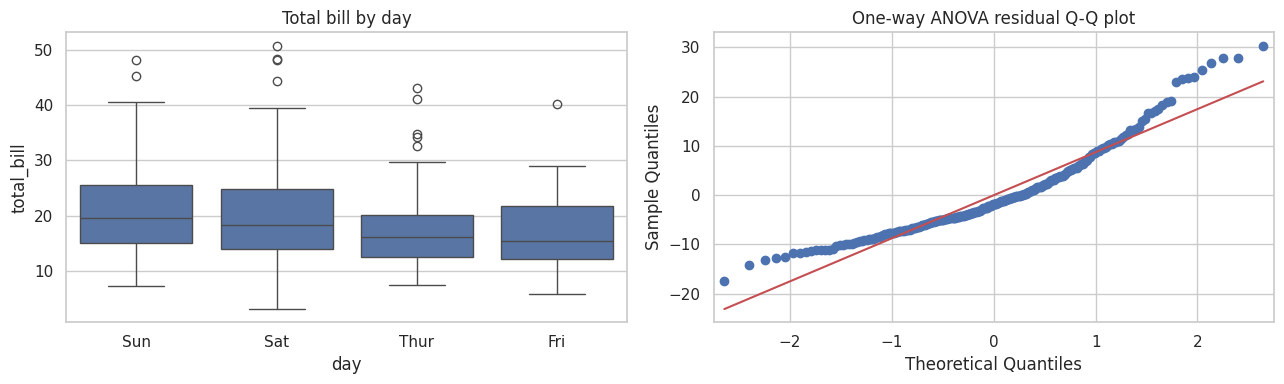

In [7]:
oneway_model = ols("total_bill ~ C(day)", data=df).fit()
oneway_table = sm.stats.anova_lm(oneway_model, typ=2)
display(oneway_table)

anova_p = oneway_table.loc["C(day)", "PR(>F)"]
print("One-way ANOVA decision:", "Reject H0" if anova_p < ALPHA else "Fail to reject H0")

tukey_day = pairwise_tukeyhsd(endog=df["total_bill"], groups=df["day"], alpha=ALPHA)
print(tukey_day)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="day", y="total_bill", ax=axes[0])
axes[0].set_title("Total bill by day")
sm.qqplot(oneway_model.resid, line="s", ax=axes[1])
axes[1].set_title("One-way ANOVA residual Q-Q plot")
plt.tight_layout()
plt.show()

## 5. Two-Way ANOVA: day and sex

**Outcome:** Total bill  
**Factors:** Day and sex

- **H₀ (day):** Mean total bill does not differ by day after accounting for sex.
- **H₀ (sex):** Mean total bill does not differ by sex after accounting for day.
- **H₀ (interaction):** The association between day and total bill does not depend on sex.

The alternative for each effect is that the corresponding effect is present. We include the day × sex interaction and use Type II sums of squares. Interpret main effects with care when the interaction is significant.

,sum_sq,df,F,PR(>F)
C(day),455.958187,3.0,1.958068,0.120991
C(sex),216.241255,1.0,2.785881,0.096424
C(day):C(sex),79.860806,3.0,0.342954,0.794284
Residual,18318.420661,236.0,NaN,NaN


C(day) p-value: 0.12099 | Not statistically significant
C(sex) p-value: 0.09642 | Not statistically significant
C(day):C(sex) p-value: 0.79428 | Not statistically significant


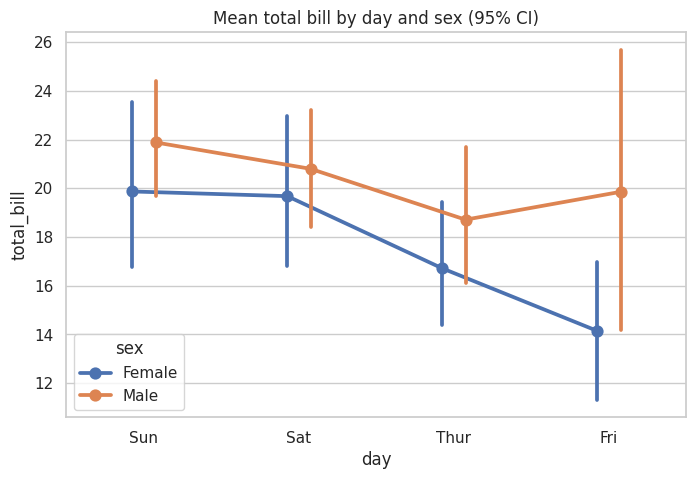

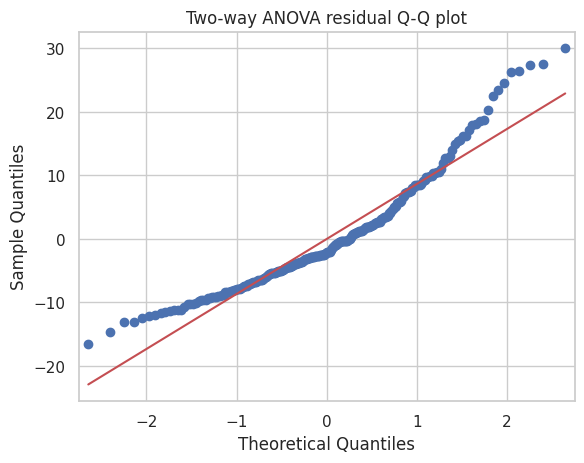

In [8]:
twoway_model = ols("total_bill ~ C(day) * C(sex)", data=df).fit()
twoway_table = sm.stats.anova_lm(twoway_model, typ=2)
display(twoway_table)

for effect in ["C(day)", "C(sex)", "C(day):C(sex)"]:
    p = twoway_table.loc[effect, "PR(>F)"]
    print(effect, "p-value:", round(p, 5),
          "|", "Significant" if p < ALPHA else "Not statistically significant")

plt.figure(figsize=(8, 5))
sns.pointplot(data=df, x="day", y="total_bill", hue="sex", errorbar=("ci", 95), dodge=0.15)
plt.title("Mean total bill by day and sex (95% CI)")
plt.show()

sm.qqplot(twoway_model.resid, line="s")
plt.title("Two-way ANOVA residual Q-Q plot")
plt.show()

## 6. Tukey HSD post-hoc analysis for day × sex groups

To explore pairwise differences between the combined day-and-sex categories, we create a combined group label and run Tukey HSD. This is a follow-up comparison across the observed combinations; interpret it alongside the two-way ANOVA interaction and account for the number of comparisons.

In [9]:
df["day_sex"] = df["day"].astype(str) + " - " + df["sex"].astype(str)

tukey_day_sex = pairwise_tukeyhsd(
    endog=df["total_bill"],
    groups=df["day_sex"],
    alpha=ALPHA
)
print(tukey_day_sex)

        Multiple Comparison of Means - Tukey HSD, FWER=0.05        
    group1        group2    meandiff p-adj   lower    upper  reject
-------------------------------------------------------------------
 Fri - Female    Fri - Male   5.7114 0.8516  -6.6688 18.0917  False
 Fri - Female  Sat - Female   5.5348 0.7258  -4.7898 15.8594  False
 Fri - Female    Sat - Male    6.657 0.4106  -2.9853 16.2993  False
 Fri - Female  Sun - Female   5.7267 0.7547  -5.2735 16.7268  False
 Fri - Female    Sun - Male   7.7417 0.2214  -1.9116  17.395  False
 Fri - Female Thur - Female   2.5698 0.9943  -7.5967 12.7362  False
 Fri - Female   Thur - Male   4.5691 0.8723  -5.6715 14.8097  False
   Fri - Male  Sat - Female  -0.1766    1.0 -10.1029  9.7496  False
   Fri - Male    Sat - Male   0.9455    1.0   -8.269   10.16  False
   Fri - Male  Sun - Female   0.0152    1.0 -10.6119 10.6424  False
   Fri - Male    Sun - Male   2.0302 0.9976  -7.1958 11.2563  False
   Fri - Male Thur - Female  -3.1417 0.9763 -12.

## 7. Findings and interpretation

Run all cells above, then use the generated tables and plots to complete this section. Do not invent conclusions before seeing the output.

### Results checklist
- **Normality:** State which variables show evidence against normality according to Shapiro-Wilk and Lilliefors, and compare with the histograms/Q-Q plots.
- **Two-sample tests:** Report the Welch t-test p-value, 95% confidence interval for the mean difference, and Mann-Whitney U p-value. Explain whether the two tests agree.
- **One-way ANOVA:** Report the F statistic and p-value. If significant, summarize the Tukey HSD pairs with adjusted p-values.
- **Two-way ANOVA:** Report the F statistics and p-values for day, sex, and the interaction. Explain the interaction before interpreting main effects.
- **Limitations:** This is observational restaurant data. Results describe associations in this sample and do not establish causation. The dataset may not represent all restaurants or customers.

### Conclusion template
The analysis examined restaurant bills and tip percentages using normality tests, independent-group tests, and ANOVA. At the 5% significance level, the results [summarize significant/non-significant findings based on your output]. The confidence interval [include the calculated interval] provides an estimate of the difference in mean tip percentage between smokers and non-smokers. Tukey HSD [summarize pairwise results]. These findings should be interpreted in light of model assumptions and the observational nature of the dataset.


## 8. References

- Seaborn Tips dataset: https://github.com/mwaskom/seaborn-data
- SciPy statistical functions: https://docs.scipy.org/doc/scipy/reference/stats.html
- Statsmodels ANOVA documentation: https://www.statsmodels.org/
- Statsmodels multiple comparisons documentation: https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html
